# Spring-mass-damper: validation, convergence, stability and performance

Experiments supporting the report. Run from the `notebooks/` folder (or anywhere: the first cell fixes the import path).

**Equation:** $m\ddot x + c\dot x + kx = 0$, $x(0)=x_0$, $\dot x(0)=v_0$.

In [2]:
import sys, os, time, cProfile, pstats, io
sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import matplotlib.pyplot as plt

from src.models import SpringDamperParams, energy
from src.analytical import exact_solution
from src.solvers import simulate, simulate_reference
from src.analysis import (error_metrics, convergence_study,
                          euler_max_stable_dt, time_method)

plt.rcParams["figure.dpi"] = 110

## 1. Validation against the exact solution (all damping regimes)
Each regime is simulated with Euler and RK4 and compared with the closed-form answer.
**Report:** which regimes were tested, the dt used, and the error metrics.

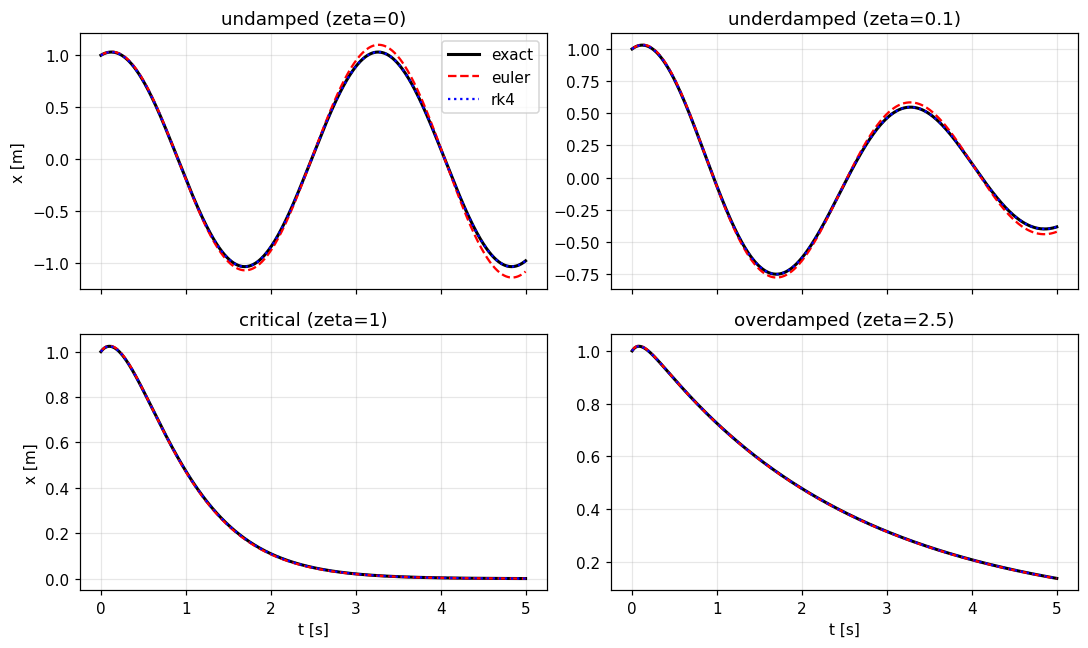

case                       method   max|x err|       RMSE x
undamped (zeta=0)          euler     1.054e-01    4.597e-02
undamped (zeta=0)          rk4       1.124e-08    5.321e-09
underdamped (zeta=0.1)     euler     4.092e-02    2.270e-02
underdamped (zeta=0.1)     rk4       5.057e-09    2.726e-09
critical (zeta=1)          euler     3.436e-03    1.825e-03
critical (zeta=1)          rk4       2.082e-09    7.633e-10
overdamped (zeta=2.5)      euler     1.747e-03    7.677e-04
overdamped (zeta=2.5)      rk4       2.800e-08    5.498e-09


In [3]:
cases = {
    "undamped (zeta=0)":      SpringDamperParams(1.0, 0.0, 4.0, 1.0, 0.5),
    "underdamped (zeta=0.1)": SpringDamperParams(1.0, 0.4, 4.0, 1.0, 0.5),
    "critical (zeta=1)":      SpringDamperParams(1.0, 4.0, 4.0, 1.0, 0.5),
    "overdamped (zeta=2.5)":  SpringDamperParams(1.0, 10.0, 4.0, 1.0, 0.5),
}
dt, T = 0.01, 5.0

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, (name, p) in zip(axes.ravel(), cases.items()):
    t_fine = np.linspace(0, T, 1000)
    ax.plot(t_fine, exact_solution(p, t_fine)[0], "k-", lw=2, label="exact")
    for m, style in (("euler", "r--"), ("rk4", "b:")):
        t, x, v = simulate(p, dt, T, m)
        ax.plot(t, x, style, label=m)
    ax.set_title(name); ax.grid(alpha=0.3)
axes[0, 0].legend()
for ax in axes[1]: ax.set_xlabel("t [s]")
for ax in axes[:, 0]: ax.set_ylabel("x [m]")
plt.tight_layout(); plt.show()

print(f"{'case':26s} {'method':6s} {'max|x err|':>12s} {'RMSE x':>12s}")
for name, p in cases.items():
    for m in ("euler", "rk4"):
        t, x, v = simulate(p, dt, T, m)
        e = error_metrics(p, t, x, v)
        print(f"{name:26s} {m:6s} {e['max_abs_x']:12.3e} {e['rmse_x']:12.3e}")

## 2. Independent check against SciPy's `solve_ivp`
The exact solution is a strong benchmark, but a second independent reference guards against a mistake shared by my analytical code and my solvers.

In [4]:
p = cases["underdamped (zeta=0.1)"]
t, x, v = simulate(p, 0.01, 5.0, "rk4")
xr, vr = simulate_reference(p, t)
xe, ve = exact_solution(p, t)
print("RK4 vs solve_ivp (DOP853):", np.max(np.abs(x - xr)))
print("exact vs solve_ivp       :", np.max(np.abs(xe - xr)))

RK4 vs solve_ivp (DOP853): 5.0562431463951896e-09
exact vs solve_ivp       : 8.874012635828876e-13


## 3. Convergence study
Halve dt repeatedly; on a log-log plot the slope is the observed order (expected 1 for Euler, 4 for RK4).

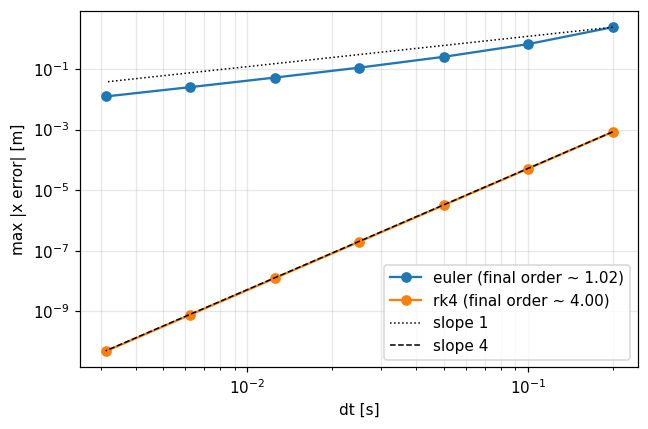

euler orders: [1.85 1.4  1.19 1.09 1.04 1.02]
rk4 orders: [4.03 4.01 4.01 4.   4.   4.  ]


In [5]:
p = cases["underdamped (zeta=0.1)"]
dts = [0.2 / 2**i for i in range(7)]
res = {m: convergence_study(p, dts, 5.0, m) for m in ("euler", "rk4")}

plt.figure(figsize=(6, 4))
for m, (err, orders) in res.items():
    plt.loglog(dts, err, "o-", label=f"{m} (final order ~ {orders[-1]:.2f})")
dts_a = np.array(dts)
plt.loglog(dts_a, res["euler"][0][0] * dts_a / dts_a[0], "k:", lw=1, label="slope 1")
plt.loglog(dts_a, res["rk4"][0][0] * (dts_a / dts_a[0])**4, "k--", lw=1, label="slope 4")
plt.xlabel("dt [s]"); plt.ylabel("max |x error| [m]")
plt.legend(); plt.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

for m, (err, orders) in res.items():
    print(m, "orders:", np.round(orders, 2))

## 4. Stability of explicit Euler
Analytical limit: $\Delta t \le -2\,\mathrm{Re}(\lambda)/|\lambda|^2$ (= $2\zeta/\omega_n$ when underdamped).
Test it numerically either side of the limit, and show the undamped energy drift.

analytical Euler limit dt_max = 0.10000000000000006


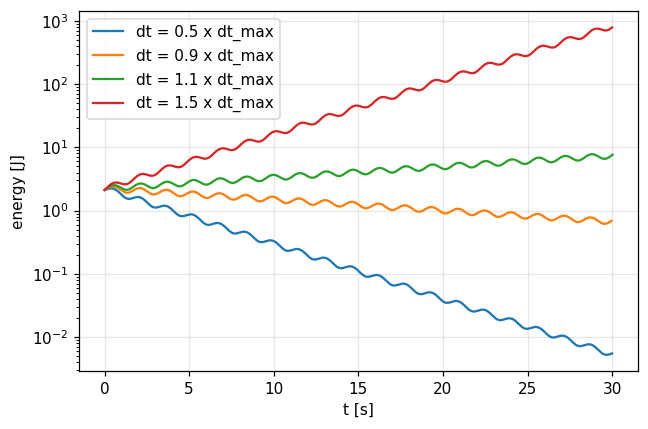

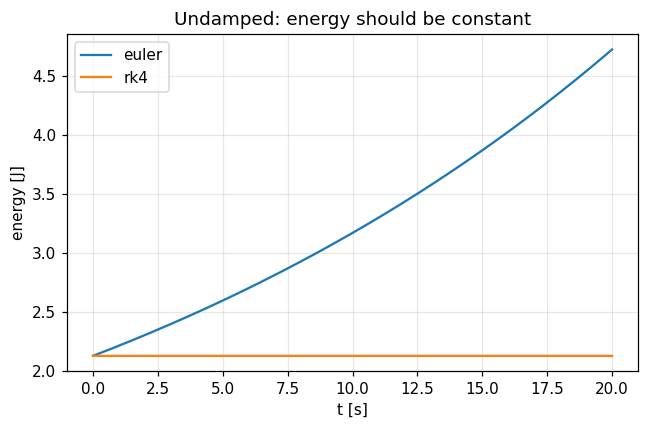

In [6]:
p = cases["underdamped (zeta=0.1)"]
dt_max = euler_max_stable_dt(p)
print("analytical Euler limit dt_max =", dt_max)

fig, ax = plt.subplots(figsize=(6, 4))
for factor in (0.5, 0.9, 1.1, 1.5):
    t, x, v = simulate(p, factor * dt_max, 30.0, "euler")
    ax.semilogy(t, energy(p, x, v), label=f"dt = {factor} x dt_max")
ax.set_xlabel("t [s]"); ax.set_ylabel("energy [J]"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

p0 = cases["undamped (zeta=0)"]
plt.figure(figsize=(6, 4))
for m in ("euler", "rk4"):
    t, x, v = simulate(p0, 0.01, 20.0, m)
    plt.plot(t, energy(p0, x, v), label=m)
plt.xlabel("t [s]"); plt.ylabel("energy [J]"); plt.title("Undamped: energy should be constant")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Performance: accuracy per unit cost
Cost per step differs (RK4 does 4 right-hand-side evaluations, Euler 1), so compare **error vs runtime**, not error vs dt.
Euler must be run at much finer steps to reach small errors, so its dt range is longer than RK4's. Where a target error lies outside what was measured, the runtime is extrapolated from the finest-step points and flagged as such.

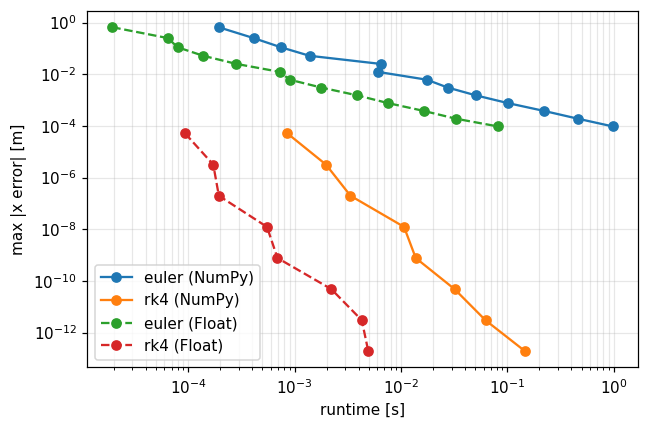

--- runtime to reach max error 0.001 m ---
NumPy euler:       77.122 ms
NumPy rk4  :        0.409 ms   (EXTRAPOLATED)
Float euler:        5.825 ms
Float rk4  :        0.045 ms   (EXTRAPOLATED)
--- runtime to reach max error 1e-06 m ---
NumPy euler:    93419.570 ms   (EXTRAPOLATED)
NumPy rk4  :        2.465 ms
Float euler:     7786.021 ms   (EXTRAPOLATED)
Float rk4  :        0.181 ms


In [7]:
from src.fast import simulate_float

p = cases["underdamped (zeta=0.1)"]
T = 5.0

def best_time(fn, dt, method, repeats):
    best = float("inf")
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(p, dt, T, method); best = min(best, time.perf_counter() - t0)
    return best

def time_to_reach(dts, errs, times, target):
    """Runtime at a target error. Interpolates on the log-log curve when the target lies inside
    the measured range. Outside it, EXTRAPOLATES from the nearest end using the observed order p:
    steps (and so runtime) scale as (error / target)**(1/p). Returns (runtime, was_extrapolated)."""
    dts, errs, times = map(np.asarray, (dts, errs, times))
    le, lt = np.log(errs), np.log(times)
    o = np.argsort(le); le, lt, d = le[o], lt[o], np.log(dts[o])
    if le[0] <= np.log(target) <= le[-1]:
        return float(np.exp(np.interp(np.log(target), le, lt))), False
    i, j = (0, 1) if np.log(target) < le[0] else (-1, -2)      # two points at the nearest end
    p = (le[i] - le[j]) / (d[i] - d[j])                        # observed order
    return float(np.exp(lt[i] + (le[i] - np.log(target)) / p)), True


n_steps = {"euler": 13, "rk4": 8}                 # Euler needs far finer steps to get small errors
curves = {}
fig, ax = plt.subplots(figsize=(6, 4))
for name, fn, style in (("NumPy", simulate, "-"), ("Float", simulate_float, "--")):
    for m in ("euler", "rk4"):
        errs, times, dts_used = [], [], [0.1 / 2**i for i in range(n_steps[m])]
        for dt in dts_used:
            t, x, v = fn(p, dt, T, m)
            errs.append(error_metrics(p, t, x, v)["max_abs_x"])
            times.append(best_time(fn, dt, m, 3 if dt >= 1e-4 else 1))
        curves[(name, m)] = (np.array(dts_used), np.array(errs), np.array(times))
        ax.loglog(times, errs, style, marker="o", label=f"{m} ({name})")
ax.set_xlabel("runtime [s]"); ax.set_ylabel("max |x error| [m]")
ax.legend(); ax.grid(True, which="both", alpha=0.3); plt.tight_layout(); plt.show()

for target in (1e-3, 1e-6):
    print(f"--- runtime to reach max error {target:g} m ---")
    for (name, m), (dts_u, errs, times) in curves.items():
        tt, extrap = time_to_reach(dts_u, errs, times, target)
        print(f"{name:5s} {m:5s}: {tt*1e3:12.3f} ms" + ("   (EXTRAPOLATED)" if extrap else ""))

### Profiling
Where does the time go? For a 2-element state, Python/NumPy call overhead usually dominates the arithmetic itself.

In [8]:
pr = cProfile.Profile()
pr.enable()
simulate(p, 0.001, 5.0, "rk4")
pr.disable()
s = io.StringIO()
pstats.Stats(pr, stream=s).sort_stats("cumulative").print_stats(8)
print(s.getvalue())

         45048 function calls in 0.134 seconds

   Ordered by: cumulative time
   List reduced from 26 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.134    0.067 c:\Users\sambi\OneDrive\Documents\Numerical 3001 Project\spring-damper\.venv\lib\site-packages\IPython\core\interactiveshell.py:3543(run_code)
        2    0.000    0.000    0.134    0.067 {built-in method builtins.exec}
        1    0.000    0.000    0.133    0.133 C:\Users\sambi\AppData\Local\Temp\ipykernel_12944\3026375045.py:1(<module>)
        1    0.009    0.009    0.133    0.133 c:\Users\sambi\OneDrive\Documents\Numerical 3001 Project\spring-damper\src\solvers.py:38(simulate)
     5000    0.077    0.000    0.124    0.000 c:\Users\sambi\OneDrive\Documents\Numerical 3001 Project\spring-damper\src\solvers.py:26(rk4_step)
    20000    0.033    0.000    0.048    0.000 c:\Users\sambi\OneDrive\Documents\Numerical 3001 Project\spring-damper\

### Rough FLOP / memory estimate (hand count - check this yourself and cite it as an estimate)
* RHS `f(y) = [v, -(c v + k x)/m]`: ~5 flops (c*v, k*x, add, divide, negate).
* Euler step: 1 RHS + `y + dt*f` (2 mult + 2 add) -> ~9 flops/step.
* RK4 step: 4 RHS (~20) + 3 stage updates (~12) + final combination (~16) -> ~48 flops/step.
* State is 2 doubles (16 bytes); stored history is `(n+1) x 2 x 8` bytes, so memory grows linearly with 1/dt.
* The arithmetic intensity is tiny and the working set fits in cache, so the measured runtime is dominated by interpreter and NumPy overhead, **not** FLOPs. Say this in the report and consider testing a pure-float (no NumPy array) step as an optimisation.

## 6. Realistic parameter cases
The normalised cases above (m = 1 kg, k = 4 N/m) are good for mathematics but not tied to a real system.
`src/cases.py` adds two cases whose parameters sit inside **published ranges** (sources in the module docstring):
a quarter-car suspension and a lightly damped steel specimen. These are *representative* values, not measurements, so
this checks the solvers on realistic scales and stiffness, **not** the model against real data.

quarter_car: wn = 7.30 rad/s (1.16 Hz), zeta = 0.2282, Euler dt_max = 6.25e-02 s
    Passive suspension of a compact car, one quarter of the body. m, k, c each chosen inside the ranges in [1]; 50 mm initial displacement is an illustrative bump. zeta ~ 0.23.
lightly_damped_specimen: wn = 31.62 rad/s (5.03 Hz), zeta = 0.0050, Euler dt_max = 3.16e-04 s
    1 kg lumped mass and zeta ~ 0.005 follow the specimens in [2]; k = 1000 N/m is illustrative (not taken from the source). Stress test: Euler is only stable for very small dt.


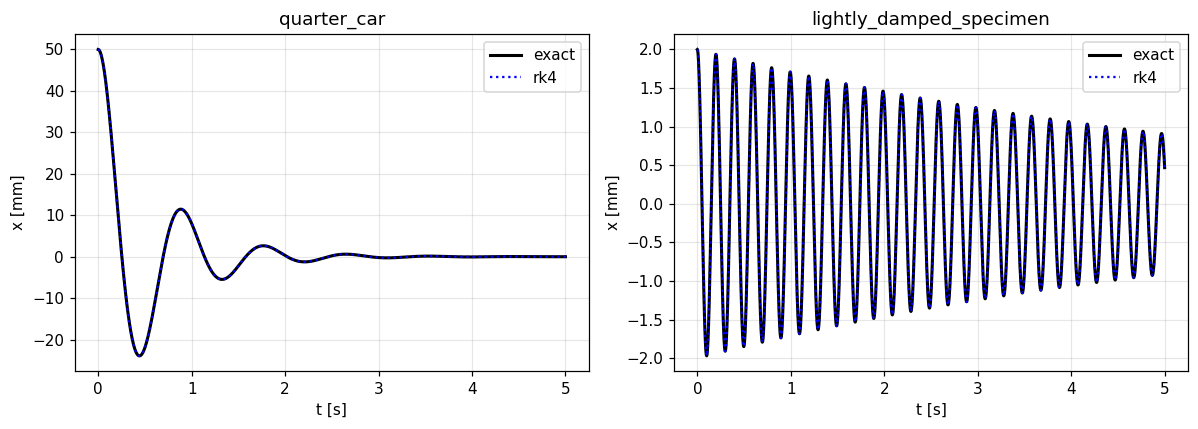

In [9]:
from src.cases import CASES

for name, case in CASES.items():
    p = case.params
    print(f"{name}: wn = {p.omega_n:.2f} rad/s ({p.omega_n/(2*np.pi):.2f} Hz), zeta = {p.zeta:.4f}, "
          f"Euler dt_max = {euler_max_stable_dt(p):.2e} s")
    print("   ", case.note)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, case) in zip(axes, CASES.items()):
    p = case.params
    t_fine = np.linspace(0, case.T, 4000)
    ax.plot(t_fine, exact_solution(p, t_fine)[0] * 1e3, "k-", lw=2, label="exact")
    t, x, v = simulate(p, 0.001 if name == "quarter_car" else 0.0001, case.T, "rk4")
    ax.plot(t, x * 1e3, "b:", label="rk4")
    ax.set_title(name); ax.set_xlabel("t [s]"); ax.set_ylabel("x [mm]"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

In [10]:
print(f"{'case':26s} {'dt [s]':>8s} {'Euler rel. err':>16s} {'RK4 rel. err':>14s}")
for name, case in CASES.items():
    p = case.params
    for dt in (1e-2, 1e-3, 1e-4):
        row = []
        for m in ("euler", "rk4"):
            t, x, v = simulate(p, dt, case.T, m)
            row.append(error_metrics(p, t, x, v)["max_abs_x"] / abs(p.x0))
        print(f"{name:26s} {dt:8.0e} {row[0]:16.2e} {row[1]:14.2e}")

case                         dt [s]   Euler rel. err   RK4 rel. err
quarter_car                   1e-02         6.34e-02       3.96e-07
quarter_car                   1e-03         5.73e-03       3.91e-11
quarter_car                   1e-04         5.70e-04       4.30e-15
lightly_damped_specimen       1e-02         9.09e+09       5.89e-03
lightly_damped_specimen       1e-03         5.01e+00       5.96e-07
lightly_damped_specimen       1e-04         1.29e-01       5.96e-11


**What to say in the report:** for the lightly damped specimen, explicit Euler is unstable for any dt above its tiny stability limit
(about 3e-4 s), so its error is enormous at dt = 1e-2 and 1e-3, while RK4 stays accurate at the same steps. For the quarter car
(zeta ~ 0.23) Euler is stable up to about 0.06 s but is still far less accurate than RK4. This shows the stability limit
2*zeta/omega_n matters most for lightly damped systems. Remember the limitation: parameters are representative, so this validates the solver
at realistic scales but does not test the physical model against measurements.

## 7. Notes for the report
* What did the validation show, and what can it *not* establish (e.g. a linear 1-DOF model says nothing about nonlinear springs)?
* Which method would recommend and why (accuracy vs cost vs stability)?
* Any surprises or bugs  found along the way?